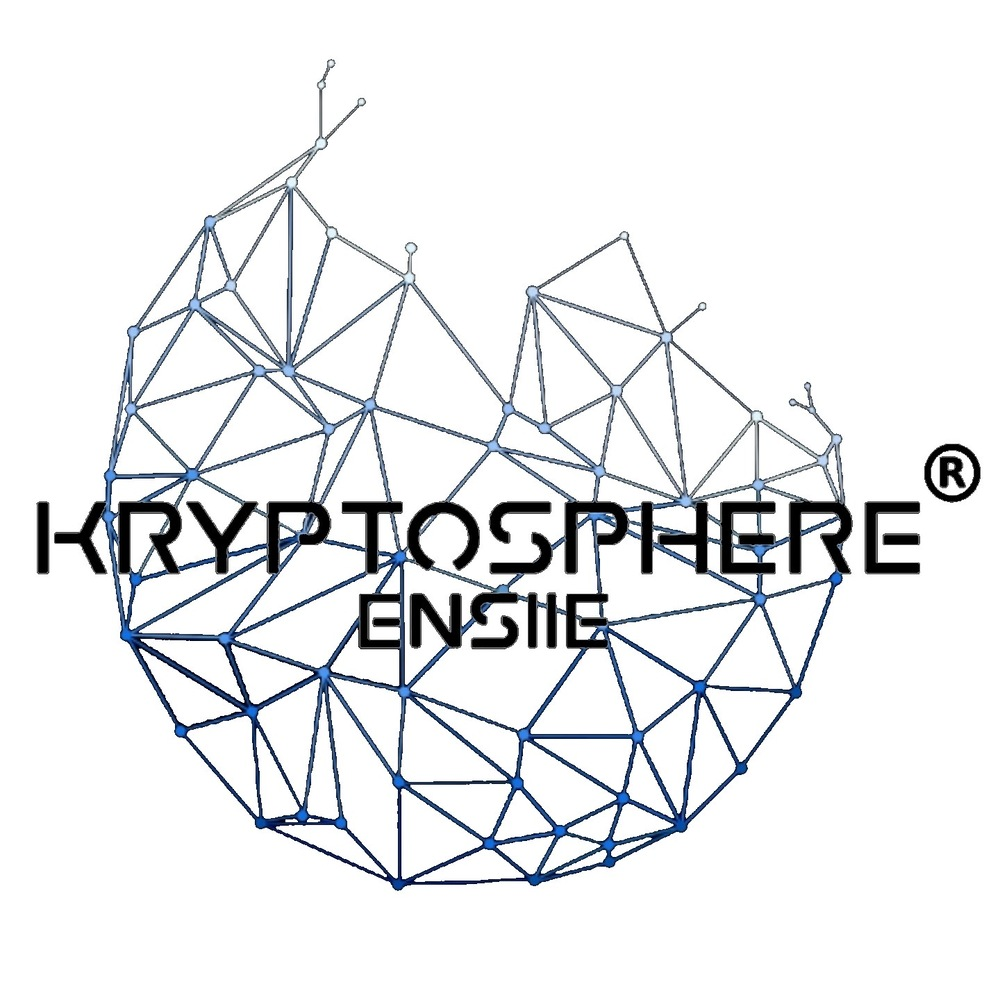🚀 L'antenne KRYPTOSHERE à l'ensIIE

KRYPTOSHERE est une association étudiante dédiée à la promotion et à la compréhension des technologies émergentes telles que la blockchain, l’intelligence artificielle et la finance numérique.

À travers des formations, conférences, meet-ups et hackathons, nous offrons à nos membres l’opportunité de développer des compétences concrètes, d’approfondir leurs connaissances et de participer activement à l’innovation dans ces domaines en pleine expansion.

Rejoindre KS, c’est faire le choix d’une expérience enrichissante, de montée en compétences rapide, et de contribution au rayonnement de l’école à travers des projets à fort impact.

# Série temporelle
Une série temporelle est une suite de données observées dans le temps, dans un ordre chronologique.  
Chaque valeur est associée à une date ou une période.

## Modèle ARIMA
Le modèle ARIMA sert à analyser et prévoir une série temporelle. Il repose sur trois idées clés.

## Composantes

1. **AR, autorégressif**  
   La valeur actuelle dépend de valeurs passées de la série.  
   Forme générale d'un AR(p) :  
   $$
   X_t = \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \varepsilon_t
   $$

2. **I, différenciation**  
   La série est transformée en prenant des différences entre observations pour supprimer la tendance et obtenir une série stationnaire.  
   Différenciation d'ordre $d$ :  
   $$
   Y_t = \nabla^d X_t
   $$

3. **MA, moyenne mobile**  
   La valeur actuelle dépend des erreurs de prédiction des périodes précédentes.  
   Forme générale d'un MA(q) :  
   $$
   X_t = \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q}
   $$

## Paramètres p, d, q

- **p** : nombre de valeurs passées utilisées dans la partie AR.  
- **d** : nombre de différenciations appliquées pour rendre la série stationnaire.  
- **q** : nombre d’erreurs passées utilisées dans la partie MA.

## Forme générale d'un modèle ARIMA(p, d, q)

Après différenciation $d$, le modèle combine AR(p) et MA(q) :

$$
Y_t = \phi_1 Y_{t-1} + \dots + \phi_p Y_{t-p}
      + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}
$$


## Méthodologie de Box-Jenkins pour ARIMA

La méthode Box-Jenkins sert à construire un modèle ARIMA en trois étapes.

1. **Identification**
   - Regarder la série pour repérer tendance ou saisonnalité.
   - Différencier si la série n’est pas stationnaire.
   - Utiliser ACF et PACF pour choisir p, d et q.

2. **Estimation**
   - Estimer les paramètres du modèle choisi.

3. **Vérification**
   - Vérifier que les résidus ressemblent à du bruit blanc.
   - Ajuster p, d ou q si nécessaire.
   - Valider le modèle avec un jeu test ou des mesures comme RMSE ou AIC.

La méthode est itérative. On recommence les étapes jusqu’à obtenir un modèle qui décrit bien la série et produit des prévisions fiables.

# Importation des packages

In [ ]:
# Author: Mouhamed Nourou Dine Cisse
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose

import warnings
warnings.filterwarnings('ignore')

# Problématique et chargement des données

# Base de données AirPassengers

La base AirPassengers est une série temporelle classique.  
Elle indique le nombre mensuel de passagers aériens internationaux et sert souvent d’exemple pour les prévisions ARIMA.

## Colonnes

- **Month** : mois et année de l’observation.  
- **Passengers** : nombre de passagers pour le mois.

La série couvre janvier 1949 à décembre 1960, soit 12 ans de données mensuelles.

In [2]:
df = pd.read_csv("AirPassengers.csv")

In [3]:
#Afficher la base de données
df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [4]:
# Renommage de la colonne
df.rename(columns={'#Passengers':'Passengers'},inplace=True)
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [5]:
# Information generales les données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       144 non-null    object
 1   Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [6]:
# Conversion de la date en datetime
from datetime import datetime
df['Month']=pd.to_datetime(df['Month'])
df

,Month,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121
...,...,...
139,1960-08-01,606
140,1960-09-01,508
141,1960-10-01,461
142,1960-11-01,390


In [7]:
# Verification
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       144 non-null    datetime64[ns]
 1   Passengers  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.4 KB


In [8]:
# Mettre la date en index de la table
df.set_index('Month',inplace=True)
df.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


# Etape 1: Identification du modèle

## Analyse des données

## Représentation graphique

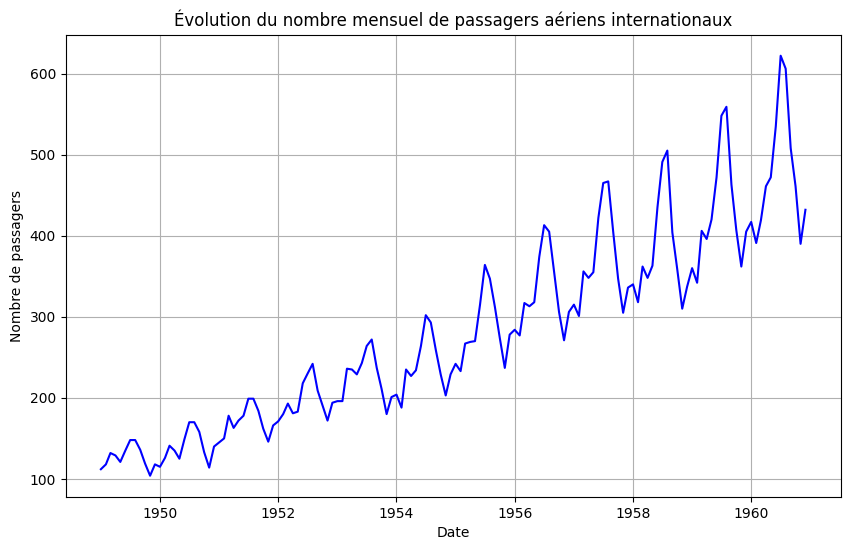

In [9]:
# Créer le graphique
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Passengers'], color='blue')
plt.title('Évolution du nombre mensuel de passagers aériens internationaux')
plt.xlabel('Date')
plt.ylabel('Nombre de passagers')
plt.grid(True)
plt.show()

### ACF et PACF

L'ACF (Autocorrelation Function) et la PACF (Partial Autocorrelation Function) servent à analyser les dépendances dans une série temporelle.

#### ACF
L'ACF mesure la corrélation de la série avec elle-même à différents décalages.  
Exemple : une ACF de 0,9 à un décalage de 2 signifie que la série ressemble beaucoup à elle-même deux périodes avant.

#### PACF
La PACF mesure la corrélation à un certain décalage en supprimant l’effet des décalages intermédiaires.  
Exemple : une PACF de 0,5 à un décalage de 3 indique une corrélation modérée après avoir pris en compte les décalages 1 et 2.

#### Utilisation
- L'ACF aide à choisir le terme MA du modèle ARIMA.  
- La PACF aide à choisir le terme AR du modèle ARIMA.

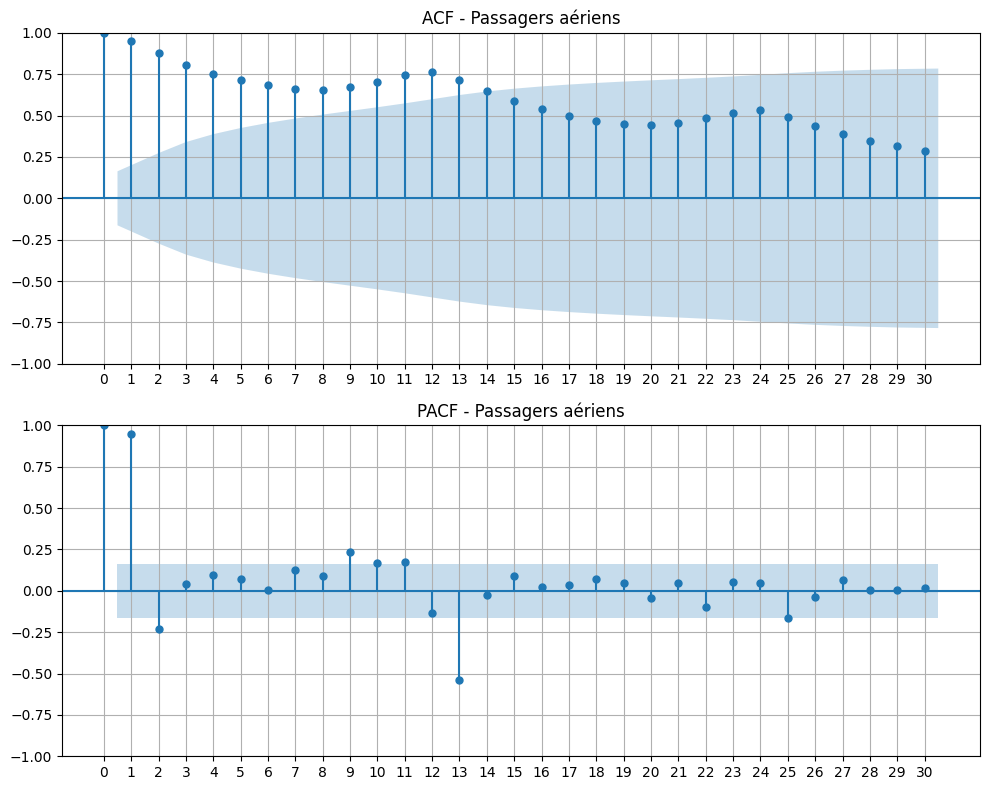

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import numpy as np

# Tracer ACF et PACF en 2 subplots
fig, axes = plt.subplots(2, 1, figsize=(10,8))

plot_acf(df['Passengers'], lags=30, ax=axes[0])
axes[0].set_title('ACF - Passagers aériens')
axes[0].set_xticks(np.arange(0,31,1))
axes[0].grid(True)

plot_pacf(df['Passengers'], lags=30, ax=axes[1])
axes[1].set_title('PACF - Passagers aériens')
axes[1].set_xticks(np.arange(0,31,1))
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [11]:
from statsmodels.tsa.stattools import adfuller

# Test de stationnarité ADF
result = adfuller(df['Passengers'])  # mettre la colonne de la série

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série est non stationnaire")

ADF Statistic: 0.8153688792060447
p-value: 0.9918802434376409
La série est non stationnaire


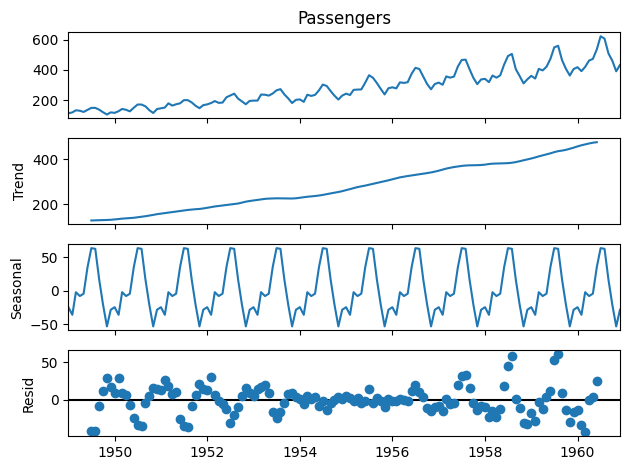

In [12]:
# Décomposition
decomp = seasonal_decompose(df['Passengers'], model='additive')

# Affichage automatique des composantes
decomp.plot()
plt.show()

## Différentciation (Stationnarisation)

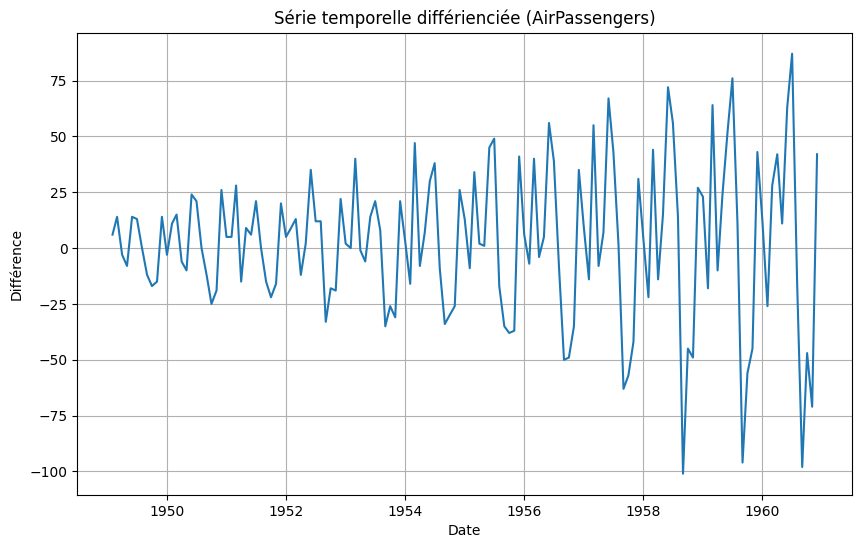

In [13]:
# Différenciation pour rendre la série stationnaire
diff_1 = df['Passengers'].diff().dropna()

# Afficher la série différienciée
plt.figure(figsize=(10, 6))
plt.plot(diff_1)
plt.title('Série temporelle différienciée (AirPassengers)')
plt.xlabel('Date')
plt.ylabel('Différence')
plt.grid(True)
plt.show()

In [14]:
from statsmodels.tsa.stattools import adfuller

# Test ADF sur la série différenciée
result = adfuller(diff_1)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série est non stationnaire")

ADF Statistic: -2.8292668241699794
p-value: 0.054213290283828236
La série est non stationnaire


In [15]:
from statsmodels.tsa.stattools import adfuller

# 2ème différenciation
diff_2 = df['Passengers'].diff(2).dropna()

# Test ADF
result = adfuller(diff_2)

print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")
print("La série est stationnaire" if result[1] < 0.05 else "La série est non stationnaire")

ADF Statistic: -2.9617
p-value: 0.0386
La série est stationnaire


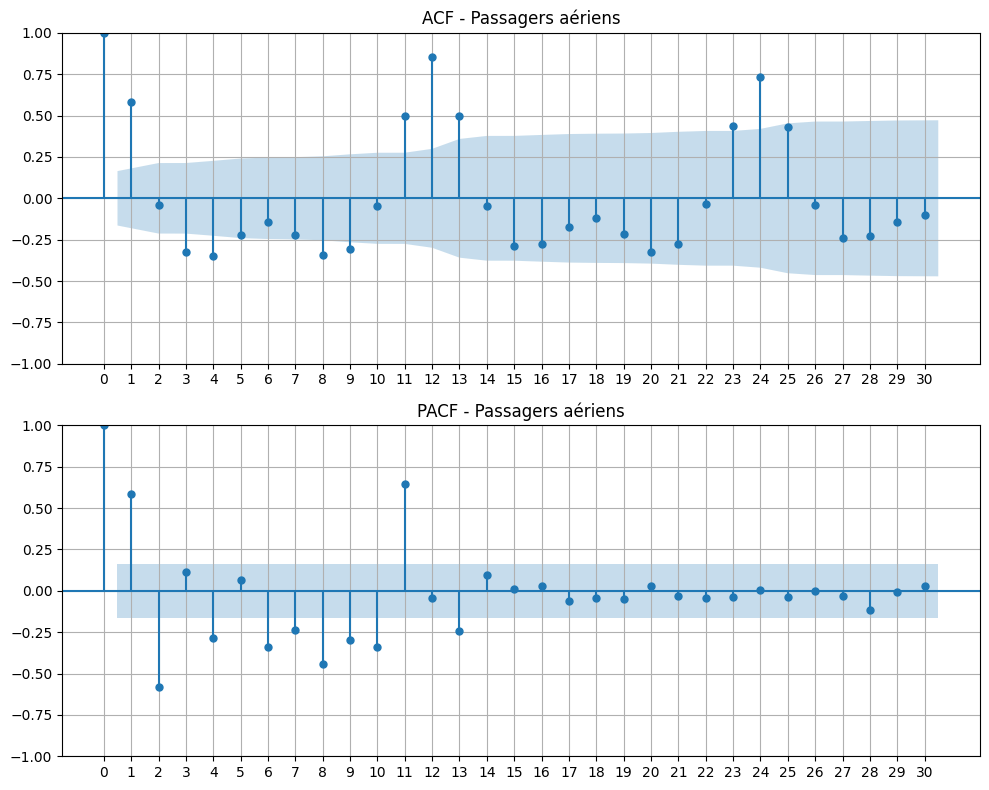

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import numpy as np

# Tracer ACF et PACF en 2 subplots
fig, axes = plt.subplots(2, 1, figsize=(10,8))

plot_acf(diff_2, lags=30, ax=axes[0])
axes[0].set_title('ACF - Passagers aériens')
axes[0].set_xticks(np.arange(0,31,1))
axes[0].grid(True)

plot_pacf(diff_2, lags=30, ax=axes[1])
axes[1].set_title('PACF - Passagers aériens')
axes[1].set_xticks(np.arange(0,31,1))
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Identification de l'ordre p,d,q

In [17]:
# Séparer les données en ensemble d'entraînement et ensemble de test
train_data = df['Passengers'][:-15]
test_data = df['Passengers'][-15:]

# Estimation du modèle

In [18]:
from statsmodels.tsa.arima.model import ARIMA

# Créer un modèle ARIMA(2,1,1)
model = ARIMA(train_data, order=(2,1,2))

# Ajuster le modèle
model_fit = model.fit()

# Afficher le résumé du modèle
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  129
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -592.714
Date:                Wed, 26 Nov 2025   AIC                           1195.429
Time:                        18:30:00   BIC                           1209.689
Sample:                    01-01-1949   HQIC                          1201.223
                         - 09-01-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.6949      0.025     67.557      0.000       1.646       1.744
ar.L2         -0.9599      0.024    -39.732      0.000      -1.007      -0.913
ma.L1         -1.8368      0.063    -28.944      0.0

# Prédiction

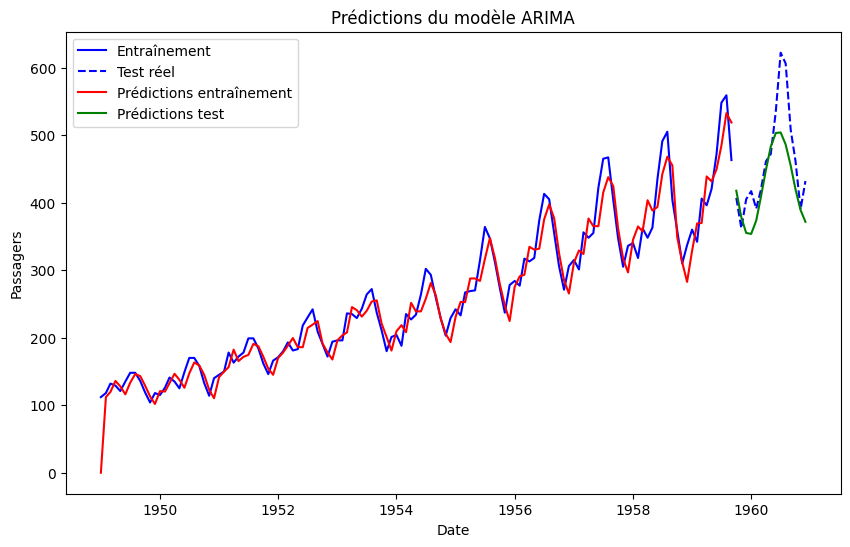

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Prédictions
train_pred = model_fit.predict(start=train_data.index[0], end=train_data.index[-1])
test_pred = model_fit.predict(start=test_data.index[0], end=test_data.index[-1])

# Tracer les résultats
plt.figure(figsize=(10,6))
plt.plot(train_data.index, train_data.values, label="Entraînement", color='blue')
plt.plot(test_data.index, test_data.values, label="Test réel", color='blue', linestyle='--')
plt.plot(train_pred.index, train_pred, label="Prédictions entraînement", color='red')
plt.plot(test_pred.index, test_pred, label="Prédictions test", color='green')

plt.xlabel("Date")
plt.ylabel("Passagers")
plt.title("Prédictions du modèle ARIMA")
plt.legend()
plt.show()

# Modèle automatique

In [20]:
#!pip install pmdarima

import pmdarima as pm

# Séparer les données en ensemble d'entraînement et ensemble de test
train_data = df['Passengers'][:-15]
test_data = df['Passengers'][-15:]

# Utiliser auto_arima pour trouver le meilleur modèle ARIMA
model = pm.auto_arima(train_data)

print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  129
Model:               SARIMAX(2, 1, 2)   Log Likelihood                -589.217
Date:                Wed, 26 Nov 2025   AIC                           1190.435
Time:                        18:33:47   BIC                           1207.547
Sample:                    01-01-1949   HQIC                          1197.388
                         - 09-01-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.6605      0.126      5.239      0.000       0.413       0.908
ar.L1          1.6235      0.041     39.770      0.000       1.543       1.703
ar.L2         -0.8951      0.041    -21.896      0.0

# Exercice: A vous de jouer !

In [21]:
from statsmodels.datasets import sunspots
data = sunspots.load_pandas().data
series = data['SUNACTIVITY']
df = series.rename("value").to_frame()
df.index = pd.date_range(start='1700-01-01', periods=len(df), freq='A')
df.head()

,value
1700-12-31,5.0
1701-12-31,11.0
1702-12-31,16.0
1703-12-31,23.0
1704-12-31,36.0


In [ ]:
# 1. Visualisation de la série et decomposition
# Afficher la serie

plt.title("Série brute")
plt.show()

# decomposer la série en utilisant une périodicité annuelle
decomp =''
# visualiser les composantes

plt.show()

# 2. Test ADF sur la série brute
result = ''
# Afficher le pvalue du test ADF
print("ADF p-value:", result[1])


# 3. Différenciation si nécessaire
df["diff1"] = ''

plt.plot(df["diff1"])
plt.title("Série différenciée (d = 1)")
plt.show()

# Test ADF sur la série différenciée
result_diff = '
# Afficher le pvalue du test ADF sur la série différenciée'
print("ADF diff p-value:", result_diff[1])


# 4. ACF pour choisir p
# Tracer ACF et PACF en 2 subplots
plt.title("ACF")
plt.show()

# Tracer PACF pour choisir q
plt.title("PACF")
plt.show()

# Choix des paramètres p, d, q
p = 0
d = 0
q = 0


# 5. Split train / test
split = int(len(df) * 0.8)
train = df["value"][:split]
test = df["value"][split:]


# 6. Modèle ARIMA
model = # modeliser ARIMA avec les paramètres p, d, q choisis
fit = model.fit()
print(fit.summary())


# 7. Analyse des résidus
res = fit.resid

plot_acf(res)
plt.title("ACF des résidus")
plt.show()


# 8. Prévision sur la période test
forecast = fit.get_forecast(steps=len(test))
pred = forecast.predicted_mean
conf = forecast.conf_int()


# 9. Plot des vraies valeurs vs prévision
plt.figure(figsize=(10, 5))
plt.plot(train.index, train, label="train")
plt.plot(test.index, test, label="test réel")
plt.plot(pred.index, pred, label="prévision", color="green")
plt.fill_between(conf.index, conf.iloc[:,0], conf.iloc[:,1], alpha=0.3)
plt.title("Prévision ARIMA vs vraies valeurs")
plt.legend()
plt.show()

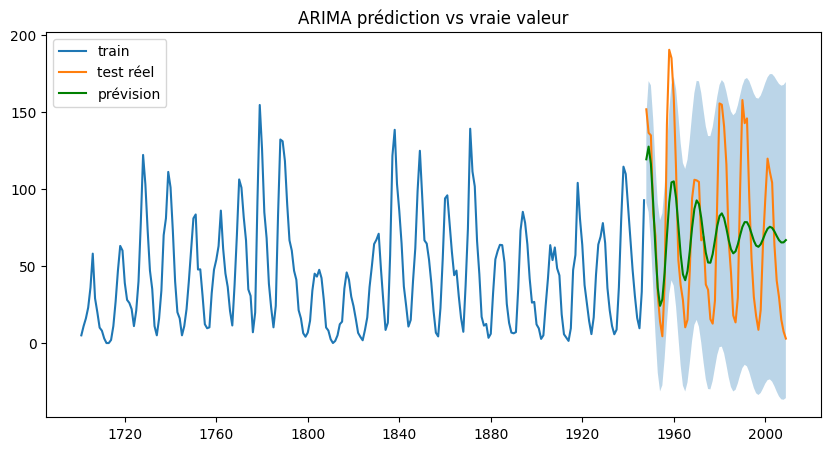

In [23]:
# Modèle ARIMA
split = int(len(df) * 0.8)
train = df["value"][:split]
test = df["value"][split:]
model = ARIMA(train, order=(2, 1, 2))
fit = model.fit()

# Prévision sur la taille du test
forecast = fit.get_forecast(steps=len(test))
pred = forecast.predicted_mean
conf = forecast.conf_int()

# Plot
plt.figure(figsize=(10, 5))
plt.plot(train.index, train, label="train")
plt.plot(test.index, test, label="test réel")
plt.plot(pred.index, pred, label="prévision", color="green")
plt.fill_between(conf.index, conf.iloc[:, 0], conf.iloc[:, 1], alpha=0.3)
plt.legend()
plt.title("ARIMA prédiction vs vraie valeur")
plt.show()